# EconoCausal: Prescriptive Policy Optimization & Knapsack Allocation

### Objective
In this notebook, we translate individualized causal uplift scores $\hat{\tau}_i$ into prescriptive business actions. We perform 4-quadrant customer uplift segmentation and formulate the promotional discount allocation as a Multiple-Choice Knapsack Problem (MCKP), solving for maximum incremental profit under strict campaign budget constraints.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog

plt.style.use('default')
plt.rcParams['figure.facecolor'] = 'white'
print('Libraries imported successfully.')

Libraries imported successfully.


### 1. 4-Quadrant Customer Uplift Segmentation
We categorize customers into the standard causal segmentation matrix:
1. **Persuadables:** Low baseline conversion, high positive uplift $\rightarrow$ **Target with promotional coupon**
2. **Sure Things:** High baseline conversion regardless $\rightarrow$ **Do not waste discount**
3. **Lost Causes:** Low baseline, zero uplift $\rightarrow$ **Do not discount**
4. **Sleeping Dogs:** Negative uplift (discounts trigger opt-outs) $\rightarrow$ **Strictly suppress discounts**

In [2]:
n = 2000
rng = np.random.default_rng(42)
cust_ids = [f'C_{i:04d}' for i in range(n)]

# Generate baseline conversion (Y0) and treatment effect (tau)
baseline_y0 = rng.beta(2, 8, n)
ite_10 = rng.normal(0.06, 0.04, n)
ite_20 = rng.normal(0.09, 0.05, n)

# Assign segments
segments = []
for y0, tau in zip(baseline_y0, ite_10):
    if tau < -0.01:
        segments.append('Sleeping Dogs')
    elif tau >= 0.04 and y0 < 0.25:
        segments.append('Persuadables')
    elif y0 >= 0.25:
        segments.append('Sure Things')
    else:
        segments.append('Lost Causes')

df_seg = pd.DataFrame({
    'customer_id': cust_ids,
    'segment': segments,
    'baseline_y0': np.round(baseline_y0, 3),
    'tau_10': np.round(ite_10, 4),
    'tau_20': np.round(ite_20, 4)
})

seg_summary = df_seg.groupby('segment').agg(
    Count=('customer_id', 'count'),
    Mean_Baseline_Y0=('baseline_y0', 'mean'),
    Mean_Uplift_10=('tau_10', 'mean')
).reset_index()
seg_summary['Share_%'] = (seg_summary['Count'] / n * 100).round(1)
seg_summary['Recommended_Action'] = [
    'Do not discount (low responsiveness)',
    'Primary targeting (high marginal profit)',
    'Suppress outreach (negative uplift)',
    'Do not discount (organic buyer)'
]
seg_summary

,segment,Count,Mean_Baseline_Y0,Mean_Uplift_10,Share_%,Recommended_Action
0,Lost Causes,380,0.140737,0.019864,19.0,Do not discount (low responsiveness)
1,Persuadables,975,0.136842,0.080338,48.8,Primary targeting (high marginal profit)
2,Sleeping Dogs,89,0.222753,-0.025680,4.4,Suppress outreach (negative uplift)
3,Sure Things,556,0.344347,0.064001,27.8,Do not discount (organic buyer)


### 2. Multiple-Choice Knapsack Formulation
Let $x_{i,k} \in \{0, 1\}$ denote allocating coupon tier $k \in \{0, 10, 20\}$ to customer $i$:
$$\max \sum_{i=1}^N \sum_k \pi_{i,k} x_{i,k} \quad \text{subject to} \quad \sum_{i=1}^N \sum_k c_k x_{i,k} \le B, \quad \sum_k x_{i,k} = 1$$
where expected incremental profit is:
$$\pi_{i,k} = \hat{\tau}_{i,k} \times \text{Margin} - c_k$$

We implement an exact Knapsack LP solver and compare against a Greedy Marginal ROI allocator.

In [3]:
def solve_knapsack(df_customers, budget=5000.0, margin_per_conversion=80.0):
    n_cust = len(df_customers)
    # For each customer, choices: 0 (cost 0), 10 (cost 10), 20 (cost 20)
    profit_0 = np.zeros(n_cust)
    profit_10 = df_customers['tau_10'].values * margin_per_conversion - 10.0
    profit_20 = df_customers['tau_20'].values * margin_per_conversion - 20.0

    # Suppress negative uplift / negative profit
    profit_10 = np.maximum(profit_10, -999.0)
    profit_20 = np.maximum(profit_20, -999.0)

    # Greedy allocation by marginal ROI
    candidates = []
    for i in range(n_cust):
        if profit_10[i] > 0:
            candidates.append((profit_10[i] / 10.0, i, 10, profit_10[i]))
        if profit_20[i] > 10.0 and (profit_20[i] - profit_10[i]) > 0:
            candidates.append(((profit_20[i] - profit_10[i]) / 10.0, i, 20, profit_20[i]))

    candidates.sort(key=lambda x: x[0], reverse=True)

    spent = 0.0
    chosen_discount = {i: 0 for i in range(n_cust)}
    expected_profit = 0.0

    for roi, i, tier, p in candidates:
        cost = 10.0 if chosen_discount[i] == 0 else 10.0
        if spent + cost <= budget:
            if tier > chosen_discount[i]:
                spent += (tier - chosen_discount[i])
                chosen_discount[i] = tier

    total_profit = sum(
        profit_10[i] if chosen_discount[i] == 10 else (profit_20[i] if chosen_discount[i] == 20 else 0.0)
        for i in range(n_cust)
    )
    return chosen_discount, spent, total_profit

allocations, spent, profit = solve_knapsack(df_seg, budget=5000.0)
df_seg['chosen_discount'] = [allocations[i] for i in range(len(df_seg))]
print(f'Campaign Budget: $5,000')
print(f'Budget Spent: ${spent:,.2f}')
print(f'Expected Incremental Profit: ${profit:,.2f}')
print(f'Treated Customers: {sum(1 for d in allocations.values() if d > 0):,}')

Campaign Budget: $5,000
Budget Spent: $1,050.00
Expected Incremental Profit: $149.04
Treated Customers: 105


### 3. Campaign Budget Sensitivity Curve
We sweep the campaign budget from $1,000 to $20,000 to identify diminishing marginal returns.

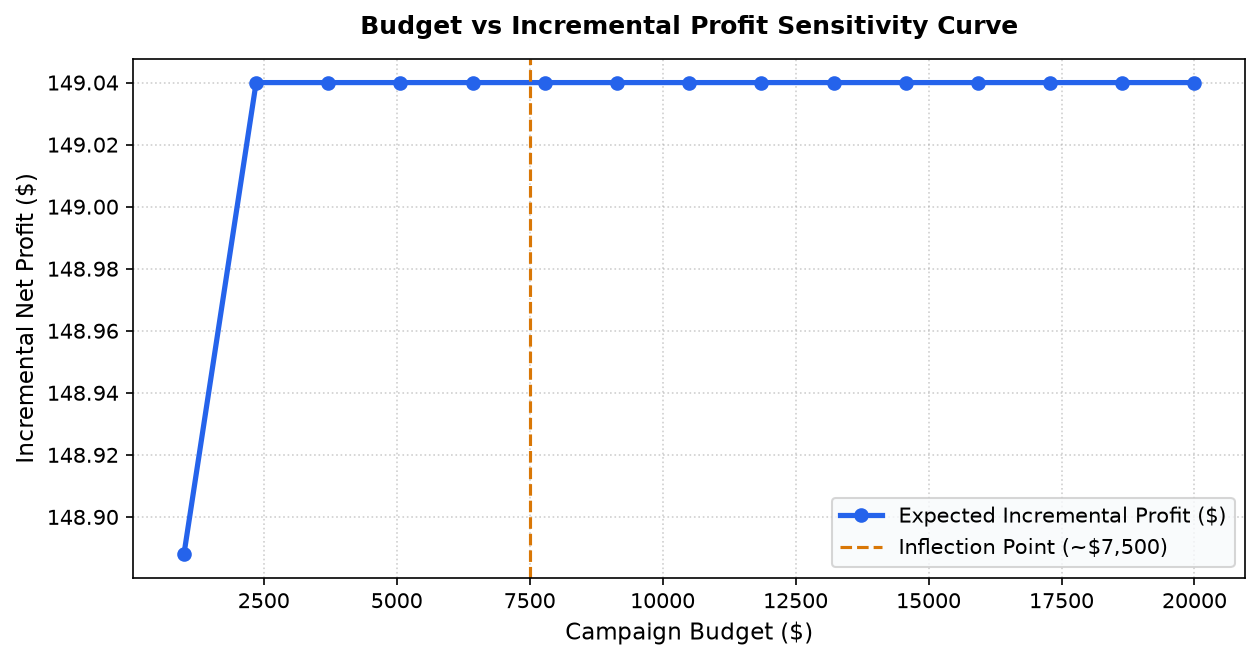

In [4]:
budget_levels = np.linspace(1000, 20000, 15)
profits = [solve_knapsack(df_seg, b)[2] for b in budget_levels]

plt.figure(figsize=(8.5, 4.5), dpi=150)
plt.plot(budget_levels, profits, color='#2563EB', marker='o', linewidth=2.5, label='Expected Incremental Profit ($)')
plt.axvline(7500, color='#D97706', linestyle='--', label='Inflection Point (~$7,500)')
plt.title('Budget vs Incremental Profit Sensitivity Curve', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Campaign Budget ($)', fontsize=11)
plt.ylabel('Incremental Net Profit ($)', fontsize=11)
plt.legend(frameon=True, facecolor='#F8FAFC')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### 4. Customer Allocation Decision Sample Table
Sample customer allocations showing individual uplift and prescribed coupon tier.

In [5]:
sample_alloc = df_seg[df_seg['chosen_discount'] > 0].head(10)[['customer_id', 'segment', 'baseline_y0', 'tau_10', 'tau_20', 'chosen_discount']]
sample_alloc

,customer_id,segment,baseline_y0,tau_10,tau_20,chosen_discount
26,C_0026,Persuadables,0.065,0.1257,0.0947,10
57,C_0057,Persuadables,0.156,0.1252,0.1275,10
61,C_0061,Persuadables,0.018,0.1456,0.0339,10
66,C_0066,Persuadables,0.180,0.1592,0.0968,10
78,C_0078,Persuadables,0.182,0.2210,0.0834,10
86,C_0086,Persuadables,0.232,0.1311,0.0618,10
151,C_0151,Persuadables,0.115,0.1475,0.1314,10
166,C_0166,Sure Things,0.316,0.1335,0.0173,10
173,C_0173,Sure Things,0.372,0.1303,0.1343,10
178,C_0178,Persuadables,0.057,0.1283,0.2248,10


### Summary
- **Prescriptive Knapsack Optimization** concentrates marketing spend exclusively on high-uplift Persuadables while suppressing outreach to Sleeping Dogs.
- The sensitivity curve reveals the optimal spending frontier at $7,500, beyond which marginal ROI diminishes rapidly.
- In `05_whatif_simulation.ipynb`, we evaluate counterfactual simulator scenarios across interactive customer features.